In [1]:
import numpy as np
import matplotlib.pyplot as plt

from som_rl.env.schedules import SchedulerConfig, FixedScheduler

plt.rcParams["figure.figsize"] = (6, 4)

In [2]:
def eval_T_floor_vs_level(cfg: SchedulerConfig, levels: np.ndarray):
    """Evaluate T and floor as functions of level for a given SchedulerConfig.

    Uses FixedScheduler just as a lightweight wrapper around BaseScheduler's
    _temperature and _floor helpers. We do not rely on its own step-based
    level interpolation here; we manually set sched.level.
    """
    sched = FixedScheduler(cfg)
    Ts = []
    floors = []
    for L in levels:
        L_int = int(L)
        sched.level = L_int
        # Choose an arbitrary step index for cases where temp/floor depend on steps.
        # For pure level-based evolution, the choice of step_idx won't matter.
        step_idx = 0
        T = sched._temperature(step_idx)
        floor = sched._floor(step_idx=step_idx, level=L_int, T=T)
        Ts.append(T)
        floors.append(floor)
    return np.array(Ts), np.array(floors)


def plot_T_floor_vs_level(cfg: SchedulerConfig, levels: np.ndarray, title: str = ""):
    Ts, floors = eval_T_floor_vs_level(cfg, levels)

    fig, ax1 = plt.subplots()
    ax2 = ax1.twinx()

    ax1.plot(levels, Ts, "-b", label="T")
    ax2.plot(levels, floors, "-r", label="floor")

    ax1.set_xlabel("level")
    ax1.set_ylabel("Temperature T", color="b")
    ax2.set_ylabel("Energy floor |ΔE|min", color="r")
    # log y axis
    ax1.set_yscale("log")
    ax2.set_yscale("log")

    if title:
        ax1.set_title(title)

    # Combine legends
    lines, labels = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines + lines2, labels + labels2, loc="best")
    plt.show()

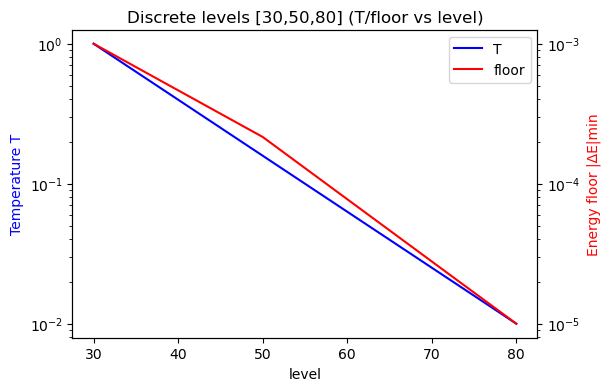

In [4]:
# Example 1: discrete levels [30, 50, 80] with T,floor evolving with level

levels_disc = np.array([30, 50, 80])

cfg_disc = SchedulerConfig(
    max_steps=2000,
    level_min=30,
    level_max=80,
    level_list=(30, 50, 80),
    # Temperature: exponential decay with level
    T_max=1.0,
    T_min=0.01,
    temp_mode="exp",
    temp_evolve_with="level",
    # Floor: ramp up with level from min to max
    min_abs_deltaE=1e-5,
    max_abs_deltaE=1e-3,
    floor_evolve_with="level",
    floor_power=1.2,
    floor_direction="decreasing",
    floor_mode="exp",
)

plot_T_floor_vs_level(cfg_disc, levels_disc, title="Discrete levels [30,50,80] (T/floor vs level)")

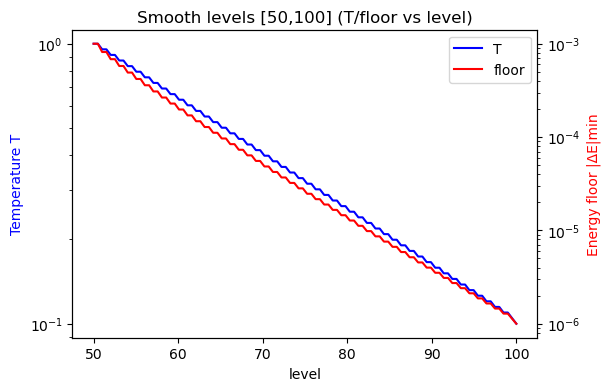

In [6]:
# Example 2: smooth level range [50, 100] with linear temperature and floor

levels_smooth = np.linspace(50, 100, 100)

cfg_smooth = SchedulerConfig(
    max_steps=2000,
    level_min=50,
    level_max=100,
    # No explicit level_list: use continuous [level_min..level_max]
    # Temperature: linear decay with level
    T_max=1.0,
    T_min=0.1,
    temp_mode="exp",
    temp_evolve_with="level",
    # Floor: ramp up with level
    min_abs_deltaE=1e-6,
    max_abs_deltaE=1e-3,
    floor_evolve_with="level",
    floor_power=0.9,
    floor_direction="decreasing",
    floor_mode="exp",
)

plot_T_floor_vs_level(cfg_smooth, levels_smooth, title="Smooth levels [50,100] (T/floor vs level)")

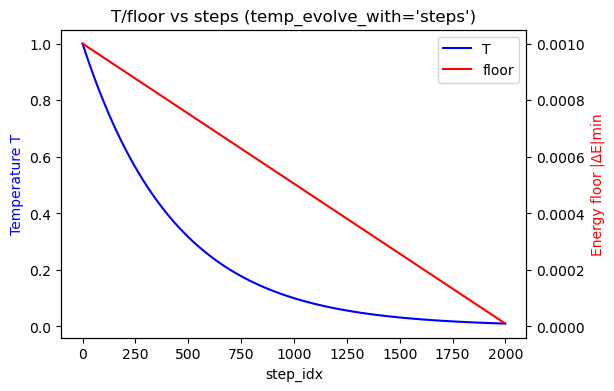

In [7]:
# Example 3: evolution with steps (for comparison)
# Here we fix level and vary step_idx indirectly by mapping levels to a step index.

steps = np.linspace(0, 1999, 100, dtype=int)

cfg_steps = SchedulerConfig(
    max_steps=2000,
    level_min=30,
    level_max=80,
    T_max=1.0,
    T_min=0.01,
    temp_mode="exp",
    temp_evolve_with="steps",
    min_abs_deltaE=1e-5,
    max_abs_deltaE=1e-3,
    floor_evolve_with="steps",
    floor_power=1.0,
    floor_direction="decreasing"
)

sched_steps = FixedScheduler(cfg_steps)
Ts_s = []
floors_s = []
for s in steps:
    T = sched_steps._temperature(int(s))
    floor = sched_steps._floor(step_idx=int(s), level=int(cfg_steps.level_min), T=T)
    Ts_s.append(T)
    floors_s.append(floor)

fig, ax1 = plt.subplots()
ax2 = ax1.twinx()

ax1.plot(steps, Ts_s, "-b", label="T")
ax2.plot(steps, floors_s, "-r", label="floor")

ax1.set_xlabel("step_idx")
ax1.set_ylabel("Temperature T", color="b")
ax2.set_ylabel("Energy floor |ΔE|min", color="r")
ax1.set_title("T/floor vs steps (temp_evolve_with='steps')")

lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines + lines2, labels + labels2, loc="best")
plt.show()